# Stochastic Solutions: A Bayesian Approach
### Ternary Distillation | Monte Carlo Simulation + Bayesian MCMC

**SimuTech Project — IIT Kanpur | Jan–Apr 2025**

The goal is to quantify how uncertainty in the feed and operating conditions affects the product composition, and then estimate the distribution of operating parameters that can explain a reference composition.

**Workflow:** simplified distillation model → 5,000 Monte Carlo runs → input/output analysis → Bayesian priors and Gaussian likelihood → 3,000-step Metropolis–Hastings chains → posterior summaries and model checks.

*This is a simplified process surrogate, not an equilibrium-stage simulator. The reference composition is a specified modeling target rather than a documented plant measurement.*

## 1. Import libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

SEED = 42
print("Libraries imported successfully")

Libraries imported successfully


## 2. Define the distillation model

The feed contains three components. Since the mole fractions sum to one,

$$z_C=1-z_A-z_B.$$

I used a simple separation factor that depends on reflux ratio $R$ and stage efficiency $\eta$:

$$s=\frac{R}{R+1}\eta.$$

The three predicted product mole fractions are

$$
\begin{aligned}
x_{D,A}&=\frac{z_A+0.3s}{1+0.6s},\\
x_{D,B}&=\frac{z_B+0.2s}{1+0.6s},\\
x_{D,C}&=\frac{1-z_A-z_B+0.1s}{1+0.6s}.
\end{aligned}
$$

The coefficients $0.3$, $0.2$ and $0.1$ describe the behavior of this simplified surrogate. They are not fitted vapor–liquid equilibrium parameters.

In [2]:
def valid_parameters(feed_A, feed_B, reflux_ratio, stage_efficiency):
    return (
        0 < feed_A < 1 and
        0.2 <= feed_B <= 0.4 and
        feed_A + feed_B < 1 and
        reflux_ratio > 0 and
        0 < stage_efficiency <= 1
    )


def simulate_ternary_distillation(feed_A, feed_B, reflux_ratio, stage_efficiency):
    if not valid_parameters(feed_A, feed_B, reflux_ratio, stage_efficiency):
        return None

    feed_C = 1 - feed_A - feed_B

    # Simple separation model
    sep_factor = (reflux_ratio / (reflux_ratio + 1)) * stage_efficiency

    xD_A = feed_A + 0.3 * sep_factor
    xD_B = feed_B + 0.2 * sep_factor
    xD_C = feed_C + 0.1 * sep_factor

    total = xD_A + xD_B + xD_C
    return np.array([xD_A / total, xD_B / total, xD_C / total])


example = simulate_ternary_distillation(0.40, 0.30, 3.0, 0.85)
print("Product composition:", example.round(4))
print("Sum of mole fractions:", example.sum())
assert np.isclose(example.sum(), 1.0)

Product composition: [0.4277 0.3092 0.2631]
Sum of mole fractions: 1.0


### Observation

The simulator takes four parameters and produces three product mole fractions. Normalization enforces a composition sum of one for each valid input. The deterministic model itself does not provide uncertainty estimates; that is what the sampling stages address.

## 3. Input uncertainty for Monte Carlo

The assumed distributions are:

| Parameter | Distribution | Reason |
|---|---|---|
| Feed A | $N(0.40,0.039^2)$ | Feed composition centered at 40% with variation |
| Feed B | $U(0.20,0.40)$ | Allowed range without a preferred value |
| Reflux ratio | $N(3,0.5^2)$ | Operation around a nominal reflux of 3 |
| Efficiency | $N(0.85,0.05^2)$ | Operation around a nominal efficiency of 85% |

Invalid combinations are rejected and redrawn, so the actual joint input distribution is the product of these densities **conditioned on the valid operating region**. The efficiency must remain between zero and one, reflux must be positive, and $z_A+z_B<1$.

## 4. Monte Carlo simulation — 5,000 runs

In [3]:
rng_mc = np.random.default_rng(SEED)
samples = 5000

# Draw each variable from its assumed distribution
feed_A = rng_mc.normal(0.40, 0.039, samples)
feed_B = rng_mc.uniform(0.20, 0.40, samples)
reflux = rng_mc.normal(3.0, 0.50, samples)
eff = rng_mc.normal(0.85, 0.05, samples)

results = []
input_values = []

for i in range(samples):
    # Resample invalid operating conditions instead of clipping them
    while not valid_parameters(feed_A[i], feed_B[i], reflux[i], eff[i]):
        feed_A[i] = rng_mc.normal(0.40, 0.039)
        feed_B[i] = rng_mc.uniform(0.20, 0.40)
        reflux[i] = rng_mc.normal(3.0, 0.50)
        eff[i] = rng_mc.normal(0.85, 0.05)

    product = simulate_ternary_distillation(feed_A[i], feed_B[i], reflux[i], eff[i])
    results.append(product)
    input_values.append([feed_A[i], feed_B[i], reflux[i], eff[i]])

results = np.array(results)
input_values = np.array(input_values)

print("Number of simulations:", len(results))
print("Output array shape:", results.shape)
assert results.shape == (5000, 3)
assert np.allclose(results.sum(axis=1), 1.0)

Number of simulations: 5000
Output array shape: (5000, 3)


In [4]:
mc_df = pd.DataFrame(
    np.column_stack([input_values, results]),
    columns=["Feed A", "Feed B", "Reflux Ratio", "Efficiency",
             "Component A", "Component B", "Component C"]
)

mc_df.head()

,Feed A,Feed B,Reflux Ratio,Efficiency,Component A,Component B,Component C
0,0.4119,0.2614,2.4771,0.8031,0.4344,0.2798,0.2858
1,0.3594,0.2863,2.6255,0.8686,0.3980,0.2992,0.3028
2,0.4293,0.3109,3.0066,0.9776,0.4509,0.3177,0.2314
3,0.4367,0.3105,3.1416,0.8564,0.4544,0.3169,0.2287
4,0.3239,0.2084,2.6875,0.8270,0.3707,0.2416,0.3878


## 5. Monte Carlo results

In [5]:
component_cols = ["Component A", "Component B", "Component C"]

mc_summary = pd.DataFrame({
    "Mean": mc_df[component_cols].mean(),
    "Std": mc_df[component_cols].std(ddof=0),
    "2.5%": mc_df[component_cols].quantile(0.025),
    "97.5%": mc_df[component_cols].quantile(0.975)
})

print("Monte Carlo composition summary (mean ± simulated SD):")
print(mc_summary.round(4))
print(f"\nComponent A: {mc_summary.loc['Component A', 'Mean']:.3f} ± "
      f"{mc_summary.loc['Component A', 'Std']:.3f}")
print("Monte Carlo standard error of the mean (A):",
      round(mc_summary.loc['Component A', 'Std'] / np.sqrt(samples), 6))

Monte Carlo composition summary (mean ± simulated SD):
               Mean     Std    2.5%   97.5%
Component A  0.4270  0.0283  0.3705  0.4828
Component B  0.3091  0.0418  0.2399  0.3779
Component C  0.2639  0.0508  0.1675  0.3576

Component A: 0.427 ± 0.028
Monte Carlo standard error of the mean (A): 0.0004


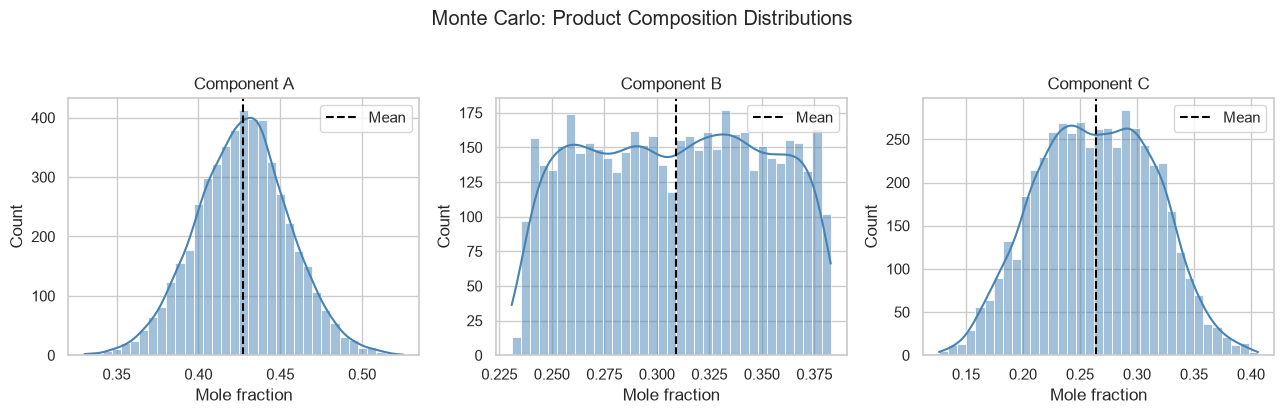

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, component in enumerate(component_cols):
    sns.histplot(mc_df[component], bins=35, kde=True, ax=axes[i], color="steelblue")
    axes[i].axvline(mc_df[component].mean(), color="black", linestyle="--", label="Mean")
    axes[i].set_xlabel("Mole fraction")
    axes[i].set_title(component)
    axes[i].legend()

plt.suptitle("Monte Carlo: Product Composition Distributions", y=1.03)
plt.tight_layout()
plt.show()

### Observation

The standard deviation describes variability in simulated product compositions under the assumed operating-condition distributions. It is different from the Monte Carlo standard error of the estimated mean. The 2.5% and 97.5% columns are empirical quantiles of simulated outcomes.

## 6. Input distributions and sensitivity

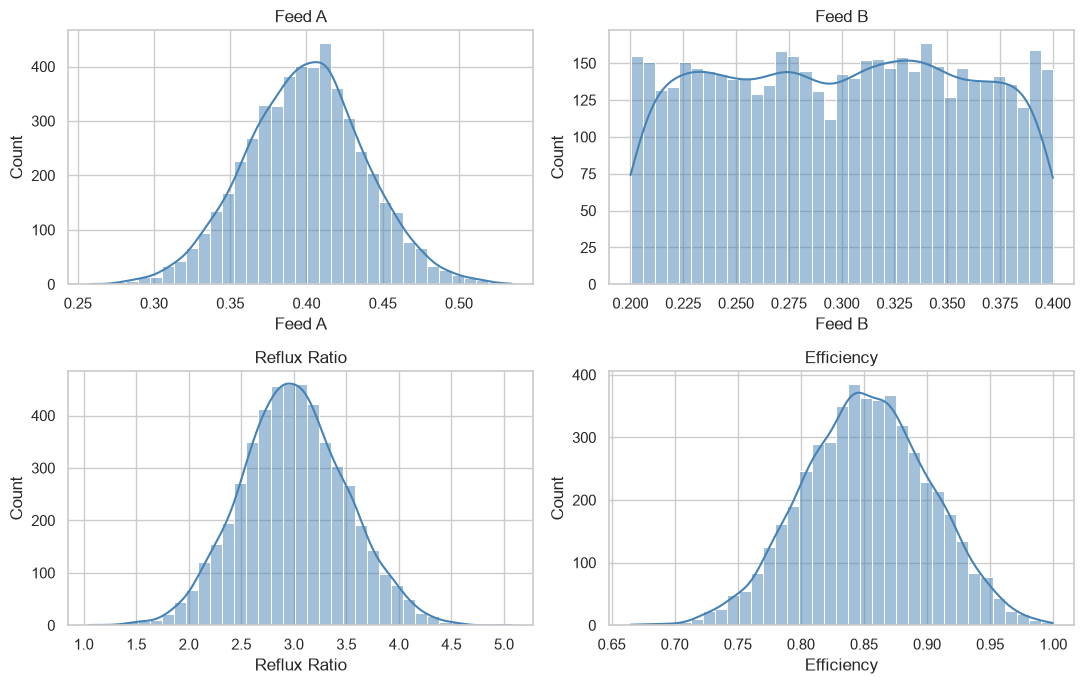

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, ax in zip(["Feed A", "Feed B", "Reflux Ratio", "Efficiency"], axes.flat):
    sns.histplot(mc_df[col], bins=35, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

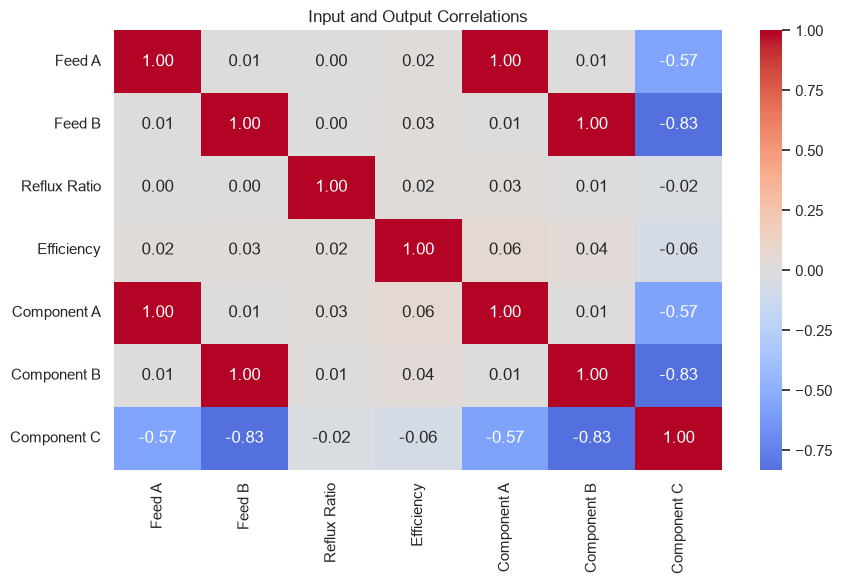

In [8]:
corr = mc_df.corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Input and Output Correlations")
plt.tight_layout()
plt.show()

## 7. Bayesian inverse problem

Now suppose we know a reference product composition:

$$\mathbf y_{\mathrm{obs}}=[0.45,\,0.35,\,0.20].$$

The unknown operating parameters are $\theta=(z_A,z_B,R,\eta)$. The target is the **joint posterior distribution**

$$\boxed{p(\theta\mid\mathbf y_{\mathrm{obs}})\propto
p(\mathbf y_{\mathrm{obs}}\mid\theta)\,p(\theta)}.$$

The prior describes plausible parameter values before seeing the reference composition. The likelihood measures how well a parameter vector predicts that composition. The product of the two is the **unnormalized posterior density** that Metropolis–Hastings uses.

We use the same bounded input assumptions from the Monte Carlo stage as the prior information for inference.

## 8. Prior distributions

In [9]:
def gaussian_pdf(x, mean, std):
    return np.exp(-0.5 * ((x - mean) / std)**2) / (std * np.sqrt(2 * np.pi))


def prior(theta):
    a, b, r, eta = theta

    # Physically invalid proposals have zero prior density
    if not valid_parameters(a, b, r, eta):
        return 0.0

    p_a = gaussian_pdf(a, 0.40, 0.039)
    p_b = 1.0 / (0.40 - 0.20)    # Uniform prior for Feed B
    p_r = gaussian_pdf(r, 3.0, 0.50)
    p_eta = gaussian_pdf(eta, 0.85, 0.05)

    # Joint prior density: product of four factors, restricted to valid inputs
    return p_a * p_b * p_r * p_eta


test_theta = np.array([0.40, 0.30, 3.0, 0.85])
print("Prior density at nominal parameters:", round(prior(test_theta), 4))
print("Prior density for invalid efficiency:", prior([0.4, 0.3, 3, 1.2]))

Prior density at nominal parameters: 325.6084
Prior density for invalid efficiency: 0.0


The product in `prior()` is a **joint density kernel**. Restricting it to the valid region introduces a joint normalizing constant, but that constant cancels when calculating the Metropolis–Hastings ratio.

A density may be greater than one; it is not the probability of an exact continuous parameter value.

## 9. Gaussian likelihood

Only two composition fractions are independent because $x_A+x_B+x_C=1$. To avoid treating three constrained fractions as three independent measurements, the likelihood uses the A and B fractions; the third is fixed by the sum-to-one constraint.

Assume an observation model with independent Gaussian errors for those two coordinates:

$$y_A\mid\theta\sim N(f_A(\theta),\sigma^2),\qquad
y_B\mid\theta\sim N(f_B(\theta),\sigma^2)$$

with $\sigma=0.02$. Omitting constants independent of $\theta$:

$$\boxed{L(\theta)\propto
\exp\left[-\frac{(y_A-f_A(\theta))^2+(y_B-f_B(\theta))^2}{2\sigma^2}\right]}.$$

The posterior is therefore proportional to **likelihood × prior**.

In [10]:
observed = np.array([0.45, 0.35, 0.20])
measurement_sigma = 0.02


def likelihood(sim, obs=observed, sigma=measurement_sigma):
    if sim is None:
        return 0.0
    sim = np.asarray(sim)
    obs = np.asarray(obs)
    error = sim[:2] - obs[:2]  # A and B are independent coordinates
    sse = np.sum(error**2)
    return np.exp(-sse / (2 * sigma**2))


def unnormalized_posterior(theta):
    # Bayes: posterior(theta | observed) ∝ likelihood(observed | theta) * prior(theta)
    return likelihood(simulate_ternary_distillation(*theta), observed) * prior(theta)


print("Reference composition:", observed)
print("Likelihood at nominal parameters:", round(likelihood(simulate_ternary_distillation(*test_theta)), 6))
print("Likelihood × prior at nominal parameters:", round(unnormalized_posterior(test_theta), 6))

Reference composition: [0.45 0.35 0.2 ]
Likelihood at nominal parameters: 0.067074
Likelihood × prior at nominal parameters: 21.840005


## 10. Metropolis–Hastings MCMC

At iteration $t$, propose

$$\theta' = \theta_t+\epsilon,\qquad \epsilon\sim N(\mathbf 0,\Sigma),$$

where the proposal standard deviations are $(0.015,0.015,0.25,0.02)$.

Because the Gaussian random-walk proposal is symmetric, the forward and backward proposal densities cancel. The acceptance probability is:

$$\boxed{\alpha(\theta_t,\theta')=
\min\left(1,
\frac{\underbrace{L(\theta')}_{\mathrm{likelihood}}\;
      \underbrace{p(\theta')}_{\mathrm{prior}}}
     {\underbrace{L(\theta_t)}_{\mathrm{likelihood}}\;
      \underbrace{p(\theta_t)}_{\mathrm{prior}}}
\right)}.$$

Draw $u\sim U(0,1)$. Accept the proposal if $u<\alpha$; otherwise retain the current state. This procedure targets the Bayesian posterior, not merely the likelihood.

In [11]:
def metropolis_hastings(iterations=3000, start=None, seed=42):
    rng = np.random.default_rng(seed)
    current = np.array(start if start is not None else [0.40, 0.30, 3.0, 0.85], dtype=float)

    if not valid_parameters(*current):
        raise ValueError("Initial parameters must satisfy the physical constraints")

    proposal_sd = np.array([0.015, 0.015, 0.25, 0.02])
    trace = []
    accepted = 0

    current_sim = simulate_ternary_distillation(*current)
    likelihood_current = likelihood(current_sim, observed)
    prior_current = prior(current)

    for _ in range(iterations):
        proposal = current + rng.normal(0, proposal_sd)
        prior_proposal = prior(proposal)

        if prior_proposal > 0:
            sim_proposal = simulate_ternary_distillation(*proposal)
            likelihood_proposal = likelihood(sim_proposal, observed)

            # Metropolis acceptance ratio = (likelihood * prior) of new
            #                               / (likelihood * prior) of current
            acceptance = min(
                1.0,
                (likelihood_proposal * prior_proposal) /
                (likelihood_current * prior_current)
            )

            if rng.random() < acceptance:
                current = proposal.copy()
                current_sim = sim_proposal
                likelihood_current = likelihood_proposal
                prior_current = prior_proposal
                accepted += 1

        trace.append(current.copy())

    return np.array(trace), accepted / iterations


trace, acceptance_rate = metropolis_hastings(iterations=3000, seed=42)
print("MCMC trace shape:", trace.shape)
print(f"Acceptance rate: {acceptance_rate:.2%}")
assert trace.shape == (3000, 4)
assert np.all([valid_parameters(*row) for row in trace])

MCMC trace shape: (3000, 4)
Acceptance rate: 59.67%


## 11. Posterior distributions

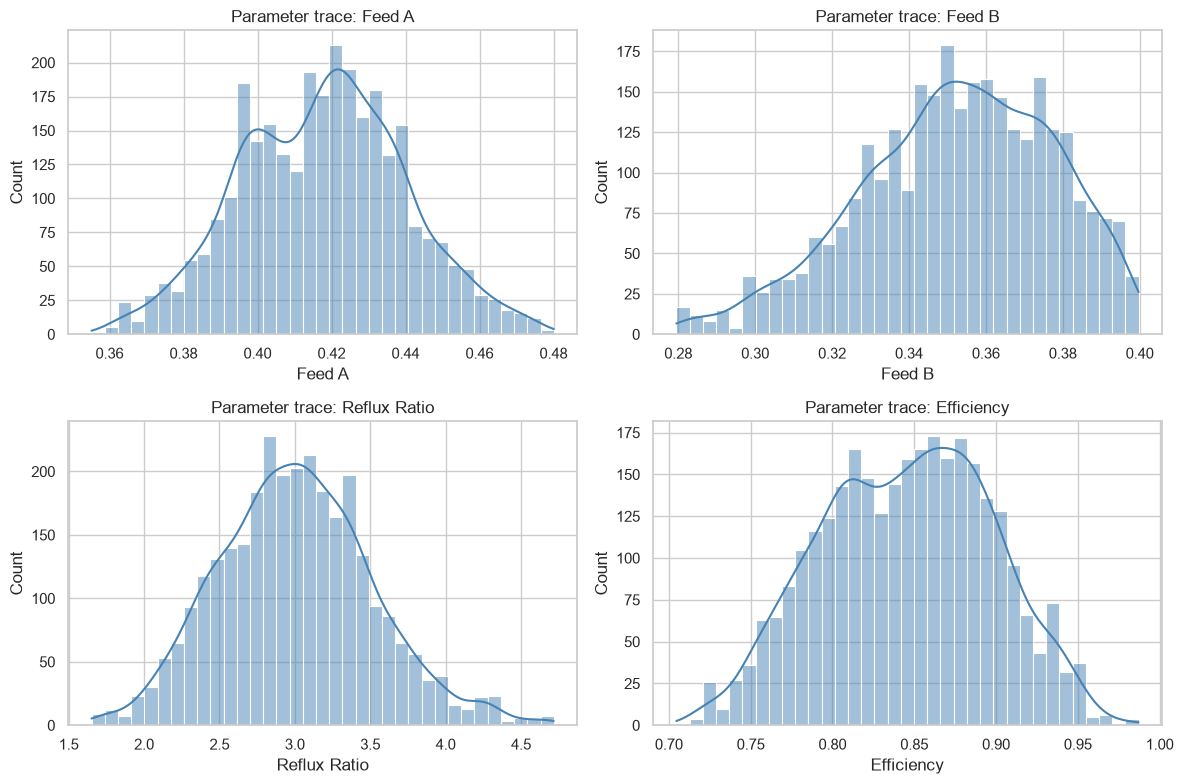

In [12]:
params = ["Feed A", "Feed B", "Reflux Ratio", "Efficiency"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    sns.histplot(trace[:, i], bins=35, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Parameter trace: {params[i]}")
    ax.set_xlabel(params[i])
plt.tight_layout()
plt.show()

A single trace is useful for visualizing sampling, but posterior summaries should be checked for dependence on the starting point. The next section runs several independently initialized 3,000-step chains and computes a basic split-$\hat R$ diagnostic. This is a diagnostic, not proof of convergence.

## 12. Multiple chains and convergence checks

In [13]:
starts = [
    [0.40, 0.30, 3.0, 0.85],
    [0.42, 0.34, 2.7, 0.83],
    [0.39, 0.29, 3.3, 0.88],
    [0.43, 0.35, 3.1, 0.80]
]

chains = []
acceptance_rates = []

for i, start in enumerate(starts):
    chain, rate = metropolis_hastings(iterations=3000, start=start, seed=200 + i)
    chains.append(chain)
    acceptance_rates.append(rate)

chains = np.array(chains)  # (number of chains, steps, parameters)
print("Chains shape:", chains.shape)
print("Acceptance rates:", [f"{r:.1%}" for r in acceptance_rates])

Chains shape: (4, 3000, 4)
Acceptance rates: ['60.1%', '61.0%', '61.1%', '61.6%']


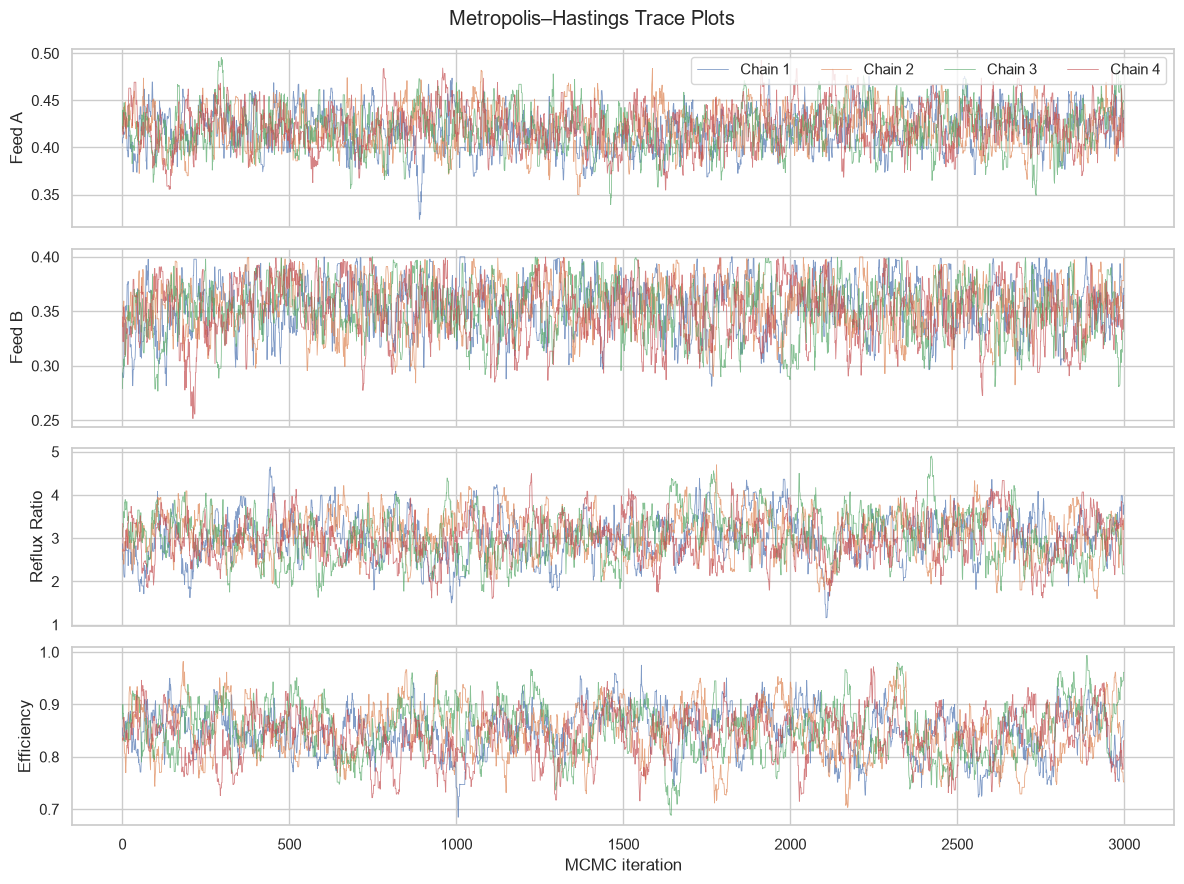

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

for j, name in enumerate(params):
    for i, chain in enumerate(chains):
        axes[j].plot(chain[:, j], linewidth=0.6, alpha=0.7,
                     label=f"Chain {i+1}" if j == 0 else None)
    axes[j].set_ylabel(name)

axes[0].legend(ncol=4, loc="upper right")
axes[-1].set_xlabel("MCMC iteration")
plt.suptitle("Metropolis–Hastings Trace Plots")
plt.tight_layout()
plt.show()

In [15]:
def split_rhat(chains):
    # Basic split-Rhat statistic, using chain halves after burn-in
    m, n, d = chains.shape
    half = n // 2
    split = np.concatenate([chains[:, :half, :], chains[:, -half:, :]], axis=0)

    n = split.shape[1]
    within = np.var(split, axis=1, ddof=1).mean(axis=0)
    between = n * np.var(split.mean(axis=1), axis=0, ddof=1)
    pooled = (n - 1) * within / n + between / n
    return np.sqrt(pooled / within)


burn_in = 500
post_chains = chains[:, burn_in:, :]
posterior_samples = post_chains.reshape(-1, 4)

posterior_df = pd.DataFrame(posterior_samples, columns=params)
posterior_summary = pd.DataFrame({
    "Mean": posterior_df.mean(),
    "Std": posterior_df.std(ddof=1),
    "2.5%": posterior_df.quantile(0.025),
    "Median": posterior_df.median(),
    "97.5%": posterior_df.quantile(0.975),
    "Split R-hat": split_rhat(post_chains)
})

print("Bayesian posterior parameter summaries:")
print(posterior_summary.round(4))

Bayesian posterior parameter summaries:
                Mean     Std    2.5%  Median   97.5%  Split R-hat
Feed A        0.4199  0.0220  0.3765  0.4199  0.4630       1.0114
Feed B        0.3529  0.0242  0.3033  0.3543  0.3954       1.0080
Reflux Ratio  3.0314  0.5169  2.0481  3.0311  4.0278       1.0106
Efficiency    0.8452  0.0475  0.7488  0.8469  0.9349       1.0148


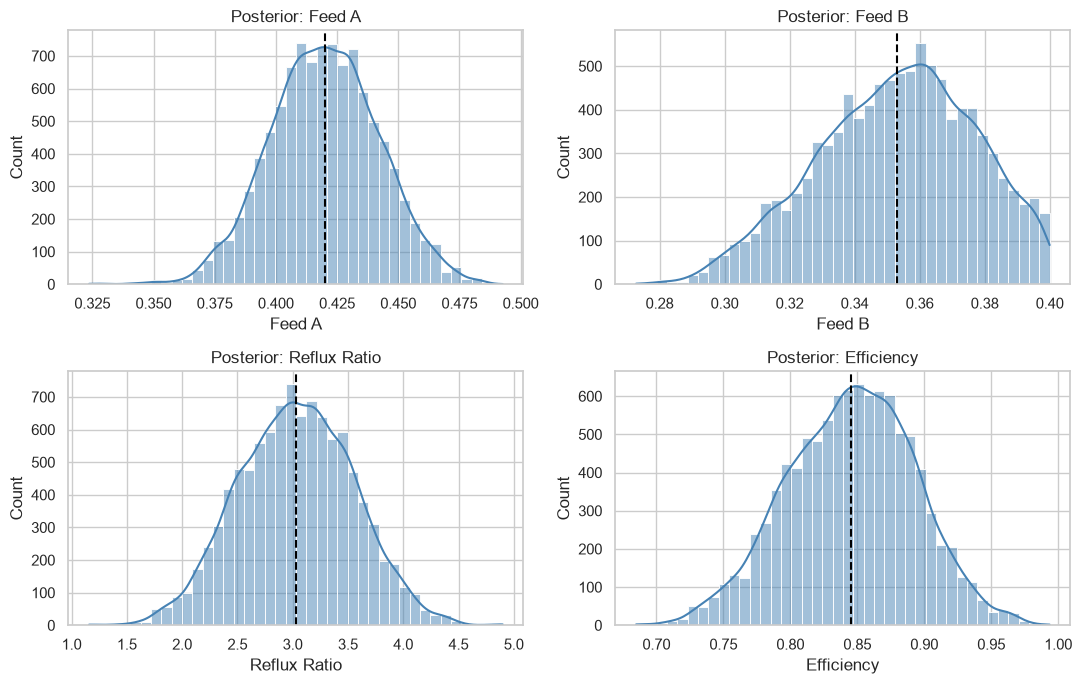

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for i, ax in enumerate(axes.flat):
    sns.histplot(posterior_df[params[i]], bins=40, kde=True, ax=ax, color="steelblue")
    ax.axvline(posterior_df[params[i]].mean(), color="black", linestyle="--")
    ax.set_title(f"Posterior: {params[i]}")

plt.tight_layout()
plt.show()

### Observation

These posterior summaries depend on the priors, likelihood, and reference composition. The split-$\hat R$ check helps assess agreement across chains; effective sample size and longer chains may be needed for stronger inference.

The process model has a structural **identifiability limitation**: $R$ and $\eta$ enter only through $s=\eta R/(R+1)$. Different reflux-efficiency combinations can produce the same output. The posterior therefore reflects both what the reference composition supports and what the priors assume.

## 13. Posterior model-fit check

In [17]:
rng_check = np.random.default_rng(123)
idx = rng_check.choice(len(posterior_samples), size=1500, replace=False)

predicted = np.array([
    simulate_ternary_distillation(*theta)
    for theta in posterior_samples[idx]
])

fit_summary = pd.DataFrame({
    "Component": ["A", "B", "C"],
    "Reference": observed,
    "Posterior model mean": predicted.mean(axis=0),
    "2.5%": np.quantile(predicted, 0.025, axis=0),
    "97.5%": np.quantile(predicted, 0.975, axis=0)
})

fit_summary.round(4)

,Component,Reference,Posterior model mean,2.5%,97.5%
0,A,0.45,0.4417,0.4087,0.4735
1,B,0.35,0.3471,0.3118,0.3783
2,C,0.20,0.2112,0.1661,0.2575


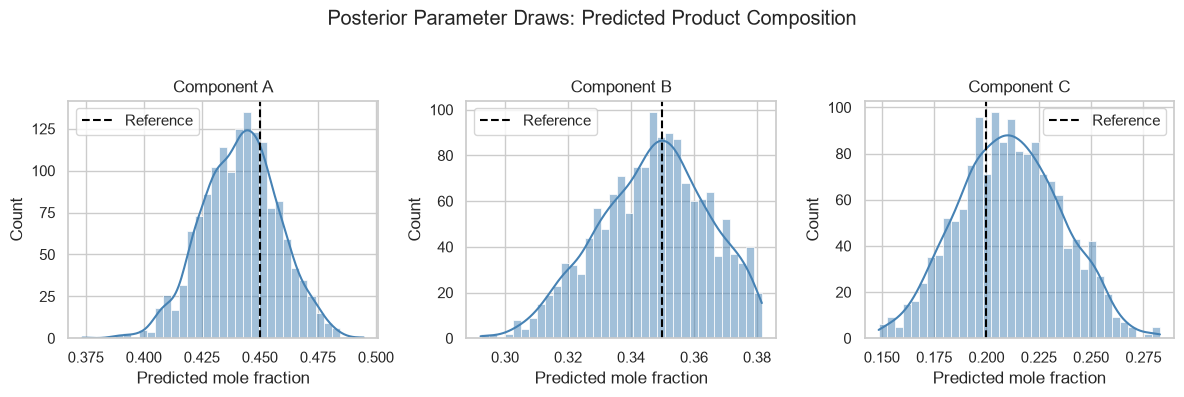

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for j, name in enumerate(["A", "B", "C"]):
    sns.histplot(predicted[:, j], bins=35, kde=True, ax=axes[j], color="steelblue")
    axes[j].axvline(observed[j], color="black", linestyle="--", label="Reference")
    axes[j].set_title(f"Component {name}")
    axes[j].set_xlabel("Predicted mole fraction")
    axes[j].legend()

plt.suptitle("Posterior Parameter Draws: Predicted Product Composition", y=1.04)
plt.tight_layout()
plt.show()

### Observation

This check tests consistency with the reference composition used for inference. It is not an independent predictive validation and does not establish performance on real plant data.

## 14. Probability of missing a composition specification

Illustrative minimum A mole fraction: 0.42
Estimated probability of falling below specification: 39.48%


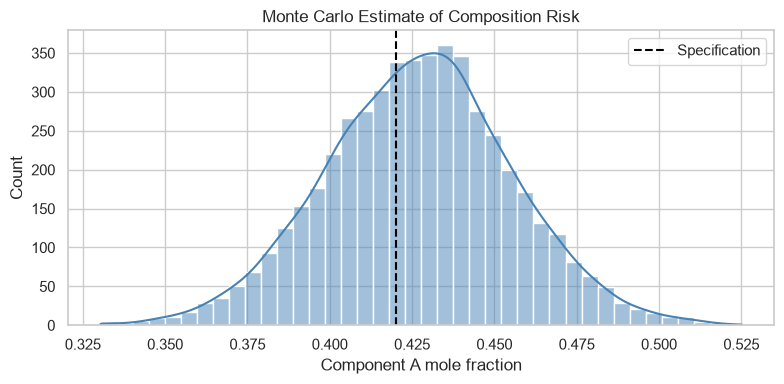

In [19]:
min_A = 0.42
prob_below = (mc_df["Component A"] < min_A).mean()

print(f"Illustrative minimum A mole fraction: {min_A:.2f}")
print(f"Estimated probability of falling below specification: {prob_below:.2%}")

plt.figure(figsize=(8, 4))
sns.histplot(mc_df["Component A"], bins=40, kde=True, color="steelblue")
plt.axvline(min_A, color="black", linestyle="--", label="Specification")
plt.xlabel("Component A mole fraction")
plt.title("Monte Carlo Estimate of Composition Risk")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Key findings

- **Forward uncertainty propagation:** 5,000 random operating scenarios gave empirical distributions of the product mole fractions, with mean, standard deviation and quantiles.
- **Bayesian inference:** the target distribution is $p(\theta\mid\mathbf y_{\mathrm{obs}})\propto L(\theta)p(\theta)$; both factors explicitly enter the MCMC acceptance ratio.
- **Metropolis–Hastings:** a symmetric Gaussian random walk proposes parameter values; the accept/reject step targets the joint posterior density.
- **Sampling diagnostics:** multiple chains, trace plots, posterior intervals and a basic split-$\hat R$ check help evaluate sampling behavior.
- **Model limitations:** this is a simplified surrogate; the inverse problem is partly non-identifiable, so posterior conclusions depend on the chosen priors and reference composition.

The main takeaway is the difference between **forward uncertainty propagation** (inputs → uncertain outputs) and **Bayesian inverse inference** (reference output → plausible input distributions).